## Question 1

### a)

In [76]:
import numpy as np
import matplotlib.pyplot as plt

In [77]:
K = 15
cf = 100
ch = 2
gamma = 0.95
T = 500
max_queue = 200

In [78]:
states = np.arange(max_queue + 1)
actions = np.array([0, 1])
arrivals = np.arange(1, 6)        
arrival_prob = 1 / len(arrivals)
n_states = len(states)
n_actions = len(actions)



Remaining customers & reward

In [79]:
remaining = np.maximum(states[None, :] - K * actions[:, None], 0)
R = cf * actions[:, None] + ch * remaining

transition probability

In [80]:
P = np.zeros((n_actions, n_states, n_states))
for ai, a in enumerate(actions):
    for s in states:
        after_dispatch = max(s - K * a, 0)
        for arrival in arrivals:
            next_state = min(after_dispatch + arrival, max_queue)
            P[ai, s, next_state] += arrival_prob

Minus Reward plus expected cost after time t, propogate backwards

In [81]:
V_finite = np.zeros((T + 1, n_states))  

for t in range(T - 1, -1, -1):
    action_values = R + gamma * (P @ V_finite[t + 1])
    V_finite[t] = np.min(action_values, axis=0)

Text(0, 0.5, 'Optimal value function')

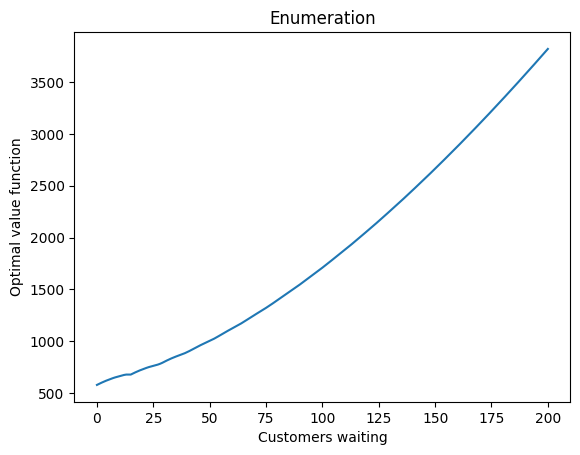

In [89]:
plt.plot(states, V_finite[0])
plt.title("Enumeration")
plt.xlabel("Customers waiting")
plt.ylabel("Optimal value function")

### b)

In [83]:
V = np.zeros(n_states)
tolerance = 1e-10
max_iterations = 100_000

for iteration in range(max_iterations):
    action_values = R + gamma * (P @ V)
    V_new = np.min(action_values, axis=0)
    if np.max(np.abs(V_new - V)) < tolerance:
        V = V_new
        break
    V = V_new

print(f"Value iteration converged after {iteration + 1} iterations.")

Value iteration converged after 519 iterations.


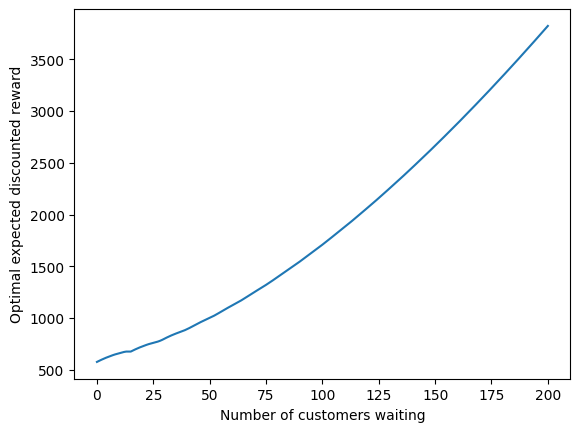

In [ ]:
plt.plot(states, V)
plt.xlabel("Number of customers waiting")
plt.ylabel("Optimal value function")
plt.show()

### c)

In [92]:
policy = np.zeros(n_states, dtype=int)
identity = np.eye(n_states)

for iteration in range(1000):
    cost_pi = R[policy, states]
    P_pi = P[policy, states, :]

    V_pi = np.linalg.solve(
        identity - gamma * P_pi,
        cost_pi
    )

    action_values = R + gamma * (P @ V_pi)
    new_policy = np.argmin(action_values, axis=0)

    if np.array_equal(new_policy, policy):
        break

    policy = new_policy

print(f"Policy iteration stopped after {iteration + 1} rounds")

Policy iteration stopped after 6 rounds


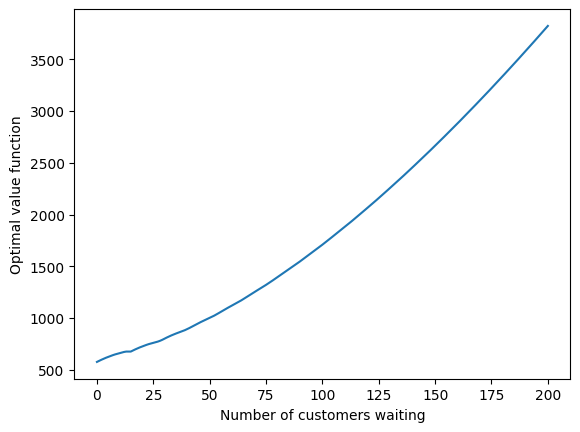

In [94]:
plt.plot(states, V_pi)
plt.xlabel("Number of customers waiting")
plt.ylabel("Optimal value function")
plt.show()